# DD-E-FRIT offline tuning: ESP32 DC-motor experiment

This notebook builds the gain database used by the ESP32 firmware and evaluates the result.

1. Load the closed-loop data recorded with fixed I-PD gains (`data/esp32/initial_run.csv`).
2. For every recorded sample, find its *k* nearest neighbours in the data and tune the I-PD gains with E-FRIT (gradient descent on the fictitious-reference cost).
3. Export the tuned database as `esp32/include/dataset.h` for the firmware, and as Structured Text for Control Expert.
4. Compare the initial run with the run that uses the tuned database (`data/esp32/dd_efrit_run.csv`).

Sample time 100 ms, controller output 8-bit PWM (0-255), speed in RPM from a quadrature encoder.

> Generated files are written to `output/esp32/`. The outputs shown are from the original run; the notebook was not re-executed after the repository was reorganised.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Every file generated by this notebook goes here, so the ESP32 and M340
# notebooks can never overwrite each other's results.
os.makedirs("output/esp32", exist_ok=True)

## 1. Initial closed-loop data

Recorded by the firmware with fixed gains (`USE_DD_EFRIT 0`) and extracted from the serial log with `esp32/tools/parse_serial_log.py`.

In [58]:
df_raw=pd.read_csv("../data/esp32/initial_run.csv")

rpm=df_raw["RPM"]

# Discard samples where the measured speed exceeds the setpoint by more than 50 RPM
# (treated as measurement spikes). An IQR outlier filter was tried earlier and is
# kept below for reference.
# Q1=rpm.quantile(0.25)
# Q3=rpm.quantile(0.75)

# IQR=Q3-Q1

# LowerBound=Q1-(1.5*IQR)
# UpperBound=Q3+(1.5*IQR)

# outliers=rpm[(rpm<LowerBound) | (rpm >UpperBound)]

df=df_raw[df_raw['RPM']<=(df_raw['SetPoint']+50)].copy()

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1199 entries, 0 to 1198
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   SetPoint  1199 non-null   float64
 1   RPM       1199 non-null   float64
 2   PWM       1199 non-null   int64  
 3   Kp        1199 non-null   float64
 4   Ki        1199 non-null   float64
 5   Kd        1199 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 56.3 KB


### Recorded response

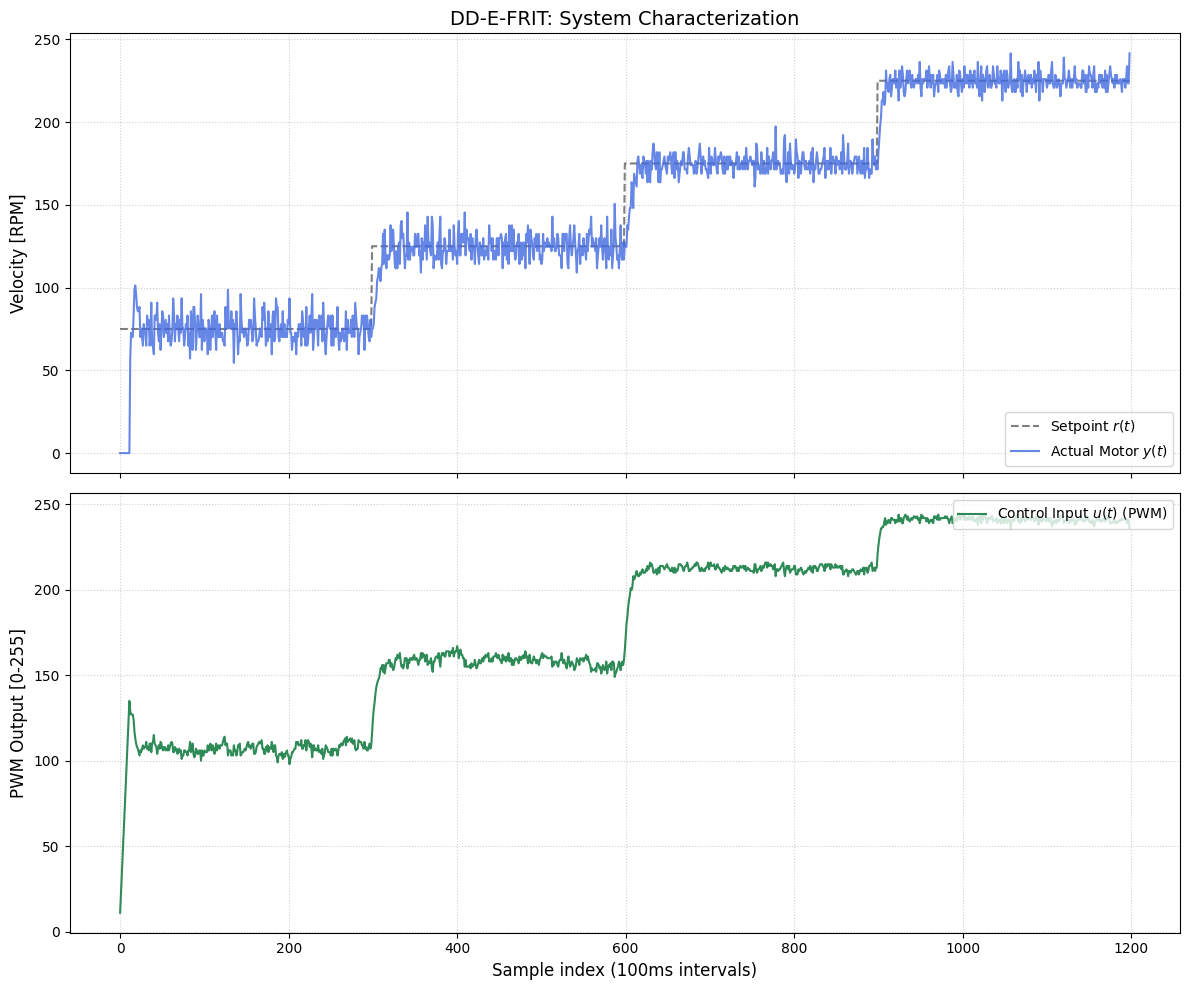

In [59]:
fig,(ax1,ax2)=plt.subplots(2,1,figsize=(12,10),sharex=True)

ax1.plot(df['SetPoint'],'k--',alpha=0.5,label='Setpoint $r(t)$')
ax1.plot(df['RPM'],'royalblue',alpha=0.8,label='Actual Motor $y(t)$')

ax1.set_title("DD-E-FRIT: System Characterization",fontsize=14)
ax1.set_ylabel("Velocity [RPM]",fontsize=12)
ax1.legend(loc='lower right')
ax1.grid(True,linestyle=':',alpha=0.6)

ax2.plot(df['PWM'],'seagreen',label='Control Input $u(t)$ (PWM)')
ax2.set_ylabel("PWM Output [0-255]",fontsize=12)
ax2.set_xlabel("Sample index (100ms intervals)",fontsize=12)
ax2.legend(loc='upper right')
ax2.grid(True,linestyle=':',alpha=0.6)

plt.tight_layout()
plt.show()

## 2. E-FRIT tuning of the database

Each record is described by the query vector φ(t) = [r(t+1), r(t), y(t), y(t−1), u(t−1), u(t−2)]. For every record, the k = 20 nearest neighbours (range-normalised L1 distance) give the starting gains, which are then tuned by gradient descent on the E-FRIT cost: the error between the measured output and the reference-model response to the fictitious reference, plus a λ-weighted control-effort term.

In [ ]:
# ---- Tuning parameters -------------------------------------------------------
# ny, nu: number of past outputs / inputs in the query vector (documentation only;
#         the vector itself is built explicitly in buildVector below)
ny=2
nu=3
k=20                  # number of nearest neighbours
ts=0.1                # sample time [s]
risetime=0.4          # reference model: desired rise time [s]
damping=1             # reference model: damping (0..1)
max_epochs=5000       # gradient-descent iterations per record (upper limit)
lr_kp=0.0001          # learning rates
lr_ki=0.0005
lr_kd=0.00001
l=0.005               # lambda: weight of the control-effort term

# Discrete second-order reference model Td(z) = P_1*z^-1 / (1 + p1*z^-1 + p2*z^-2),
# shaped by the desired rise time and damping.
def calculateReferenceModel (ts, risetime, damping):
    rho=ts/risetime
    mu=0.25*(1-damping)+0.51*damping
    p1=-2*np.exp(-rho/(2*mu))*np.cos(np.sqrt(4*mu-1)*rho/(2*mu))
    p2=np.exp(-rho/mu)
    P_1=1+p1+p2

    return p1, p2, P_1 

# Differences of the closed-loop data at sample i: dy, du and d2y.
def checkDifferentials(y0, u0, i):
    dy0=y0[i]-y0[i-1]
    du0=u0[i]-u0[i-1]

    d2y=y0[i]-2*y0[i-1]+y0[i-2]

    return dy0, du0, d2y

# Query vector phi(i) = [r(i+1), r(i), y(i), y(i-1), u(i-1), u(i-2)].
def buildVector(i):
    return [setpoint[i+1], setpoint[i], rpm[i], rpm[i-1], pwm[i-1], pwm[i-2]]

# L1 distance between two query vectors, each element scaled by its data range.
def distanceCalc(queryPhi, infoPhi):
    total=0

    for q, d, r in zip(queryPhi, infoPhi, ranges):
        total+=abs(q-d)/r

    return total

# Closed-loop data (r, y, u) and the gains that were active when it was recorded.
setpoint=df["SetPoint"].values
rpm=df["RPM"].values
pwm=df["PWM"].values
kp=df["Kp"].values
ki=df["Ki"].values
kd=df["Kd"].values

# Normalisation ranges for the six elements of the query vector.
ranges=[
    setpoint.max()-setpoint.min(),
    setpoint.max()-setpoint.min(),
    rpm.max()-rpm.min(),
    rpm.max()-rpm.min(),
    pwm.max()-pwm.min(),
    pwm.max()-pwm.min(),
]

# The tuned database starts as a copy of the recorded gains.
optimized_kp=np.copy(kp)
optimized_ki=np.copy(ki)
optimized_kd=np.copy(kd)

p1, p2, P_1=calculateReferenceModel(ts, risetime, damping)

# fs scales the input-increment term to the same magnitude as the tracking term.
fs=np.sqrt(np.var(setpoint-rpm)/np.var(np.diff(pwm)))

# ---- E-FRIT tuning of every database record ---------------------------------
for query_idx in range (2, len(setpoint)-1):
    # 1) k nearest neighbours of this record (excluding itself)
    distances=[]

    infoVector=buildVector(query_idx)

    for j in range(2, len(setpoint)-1):
        if query_idx==j:
            continue
        
        query=buildVector(j)

        d=distanceCalc(query, infoVector)
        distances.append((d,j))

    distances.sort(key=lambda x: x[0])
    neighbors=distances[:k]

    # 2) Initial gains: weighted average of the neighbours' gains, weights ~ exp(-distance)
    exp_values=[np.exp(-n[0]) for n in neighbors]
    total_exp=sum(exp_values)
    weights=[e/total_exp for e in exp_values]

    kp_opt=sum(weights[w]*kp[neighbors[w][1]] for w in range(k))
    ki_opt=sum(weights[w]*ki[neighbors[w][1]] for w in range(k))
    kd_opt=sum(weights[w]*kd[neighbors[w][1]] for w in range(k))

    print(f"Optimizing Row {query_idx}")
    print(f"Initial Local PID: {kp_opt:.4f}, {ki_opt:.4f}, {kd_opt:.4f}")

    r_tilda=np.zeros(len(setpoint))
    y_ref=np.zeros(len(setpoint))
    x0=np.zeros(len(setpoint))
    diff_u_tilda=np.zeros(len(setpoint))

    prev_epoch=0

    # 3) Gradient descent on the weighted E-FRIT cost
    for epoch in range(max_epochs):
        epoch_cost=0
        kp_grad=0
        ki_grad=0
        kd_grad=0
    

        # Fictitious reference r~ for the current gains and its reference-model response y_ref
        for i in range(2, len(setpoint)):
            dy0, du0, d2y=checkDifferentials(rpm, pwm, i)

            r_tilda[i]=rpm[i]+(du0+kp_opt*dy0+kd_opt*d2y)/ki_opt
            y_ref[i]=r_tilda[i-1]*P_1-y_ref[i-1]*p1-y_ref[i-2]*p2

    
        for w_idx in range(k):
            idx=neighbors[w_idx][1]
            w=weights[w_idx]

            if idx >= len(setpoint)-1: 
                continue

            dy0, du0, d2y=checkDifferentials(rpm, pwm, idx)
            dy_ref=y_ref[idx]-y_ref[idx-1]
            d2y_ref=y_ref[idx]-2*y_ref[idx-1]+y_ref[idx-2]

            x0[idx]=du0+kp_opt*dy0+kd_opt*d2y
            diff_u_tilda[idx]=ki_opt*(r_tilda[idx]-y_ref[idx])-kp_opt*dy_ref-kd_opt*d2y_ref

            err=rpm[idx+1]-y_ref[idx+1] 

            # Cost: tracking error + (l*fs)-weighted fictitious input increment
            epoch_cost+=w*0.5*((err)**2+l*fs*(diff_u_tilda[idx])**2) 

            kp_grad+=w*(-err*P_1*dy0/ki_opt+l*fs*diff_u_tilda[idx]*(dy0-dy_ref))
            ki_grad+=w*(err*P_1*x0[idx]/(ki_opt**2)+l*fs*diff_u_tilda[idx]*(rpm[idx]-y_ref[idx]))
            kd_grad+=w*(-err*P_1*d2y/ki_opt+l*fs*diff_u_tilda[idx]*(d2y-d2y_ref))
        

        # Gradient step, then clamp the gains to a safe range
        kp_opt=kp_opt-(lr_kp*kp_grad)
        ki_opt=ki_opt-(lr_ki*ki_grad)
        kd_opt=kd_opt-(lr_kd*kd_grad)

        if kp_opt<0.1: 
            kp_opt=0.1
        elif kp_opt>3.0: 
            kp_opt=3.0

        if ki_opt<0.1: 
            ki_opt=0.1
        elif ki_opt>5.0: 
            ki_opt=5.0

        if kd_opt<0.0: 
            kd_opt=0.0
        elif kd_opt>0.5: 
            kd_opt=0.5

        if epoch % 100==0:
            print(f"Epoch {epoch}| Cost:{epoch_cost:.6f}| PID: {kp_opt:.4f}, {ki_opt:.4f}, {kd_opt:.4f}")

        # Stop once the cost changes by less than 0.01 between epochs
        if np.abs(prev_epoch-epoch_cost) < 0.01:
            print(f'Converged at: {epoch}')
            break

        prev_epoch=epoch_cost
    
    optimized_kp[query_idx]=kp_opt
    optimized_ki[query_idx]=ki_opt
    optimized_kd[query_idx]=kd_opt
    print(f"Row {query_idx} Final PID: {kp_opt:.4f}, {ki_opt:.4f}, {kd_opt:.4f}")

# Rows 0-1 and the last row have no complete query vector, so they are dropped.
new_dataset={
    "SetPoint": setpoint,
    "RPM": rpm,
    "PWM": pwm,
    "Kp": optimized_kp,
    "Ki": optimized_ki,
    "Kd": optimized_kd
}

optimized_df = pd.DataFrame(new_dataset)
optimized_df = optimized_df.iloc[2:-1].reset_index(drop=True)
optimized_df.to_csv("output/esp32/DD_E_FRIT_Optimized_Dataset.csv", index=False)

Optimizing Row 2
Initial Local PID: 0.9158, 0.3528, 0.0515
Epoch 0| Cost:134.340394| PID: 0.9164, 0.3680, 0.0515
Converged at: 34
Row 2 Final PID: 0.9435, 0.4290, 0.0532
Optimizing Row 3
Initial Local PID: 0.9122, 0.3541, 0.0512
Epoch 0| Cost:133.002262| PID: 0.9128, 0.3669, 0.0513
Converged at: 32
Row 3 Final PID: 0.9381, 0.4189, 0.0528
Optimizing Row 4
Initial Local PID: 0.9019, 0.3567, 0.0505
Epoch 0| Cost:130.929960| PID: 0.9026, 0.3666, 0.0506
Converged at: 29
Row 4 Final PID: 0.9261, 0.4071, 0.0520
Optimizing Row 5
Initial Local PID: 0.9327, 0.3534, 0.0521
Epoch 0| Cost:128.697661| PID: 0.9333, 0.3608, 0.0522
Converged at: 24
Row 5 Final PID: 0.9512, 0.3884, 0.0532
Optimizing Row 6
Initial Local PID: 0.8762, 0.3646, 0.0485
Epoch 0| Cost:123.785013| PID: 0.8770, 0.3668, 0.0485
Converged at: 18
Row 6 Final PID: 0.8926, 0.3754, 0.0495
Optimizing Row 7
Initial Local PID: 0.8665, 0.3699, 0.0481
Epoch 0| Cost:119.160362| PID: 0.8674, 0.3672, 0.0481
Converged at: 13
Row 7 Final PID: 0.8

## 3. Export the tuned database

### C header for the ESP32 firmware

In [ ]:
# Write the tuned database as a C header for the firmware (esp32/include/dataset.h).
def make_header():
    
    with open('output/esp32/DD_E_FRIT_Optimized_Dataset.csv', 'r') as f:
        lines=f.readlines()

    data_lines=lines[1:]
    dataset_size=len(data_lines)

    with open('../esp32/include/dataset.h', 'w') as h_file:
        h_file.write("#ifndef DATASET_H\n")
        h_file.write("#define DATASET_H\n\n")
        h_file.write(f"const int dataset_size={dataset_size};\n\n")

        h_file.write("// Structure: {SetPoint, RPM, PWM}\n")
        h_file.write("const float infoMatrix[][3] = {\n")
        for line in data_lines:
            row = line.strip().split(',') 
            # row[0] = SetPoint, row[1] = RPM, row[2] = PWM
            h_file.write(f"    {{{row[0]}, {row[1]}, {row[2]}}},\n")
        h_file.write("};\n\n")

        h_file.write("// Structure: {Kp, Ki, Kd}\n")
        h_file.write("const float pidMatrix[][3] = {\n")
        for line in data_lines:
            row = line.strip().split(',')
            # row[3] = Kp, row[4] = Ki, row[5] = Kd
            h_file.write(f"    {{{row[3]}, {row[4]}, {row[5]}}},\n")
        h_file.write("};\n\n")

        h_file.write("#endif\n")

make_header()

<>:9: SyntaxWarning: invalid escape sequence '\i'
<>:9: SyntaxWarning: invalid escape sequence '\i'
C:\Users\baron\AppData\Local\Temp\ipykernel_27768\717287091.py:9: SyntaxWarning: invalid escape sequence '\i'
  with open ('..\include\dataset.h', 'w') as h_file:


### Structured Text for Control Expert

In [14]:
# Write the same database as Structured Text initialisation code for Control Expert.
def make_st():
    df=pd.read_csv("output/esp32/DD_E_FRIT_Optimized_Dataset.csv")
    dataset_size=len(df)

    with open("output/esp32/data_init.txt", "w", newline="\n") as st_file:
        st_file.write ("IF %S21 THEN \n")
        st_file.write(f"    DATASET_SIZE := {dataset_size};\n")
        st_file.write("    // Structure: {SetPoint, RPM, PWM}\n\n")

        for i, row in df.iterrows():
            st_file.write(f"    infoMatrix[{i},0] := {row['SetPoint']:.4f};\n")
            st_file.write(f"    infoMatrix[{i},1] := {row['RPM']:.4f};\n")
            st_file.write(f"    infoMatrix[{i},2] := {row['PWM']:.4f};\n")
            st_file.write(f"    pidMatrix[{i},0] := {row['Kp']:.6f};\n")
            st_file.write(f"    pidMatrix[{i},1] := {row['Ki']:.6f};\n")
            st_file.write(f"    pidMatrix[{i},2] := {row['Kd']:.6f};\n")
            st_file.write(f"    bDataLoaded := TRUE;\n")
            st_file.write("     \n")
        
        st_file.write ("END_IF;")
make_st()

### Importable Control Expert `.xst` section

In [13]:
from datetime import datetime

# Same export wrapped as a Control Expert .xst section that can be imported directly.
def make_xst():
    df = pd.read_csv("output/esp32/DD_E_FRIT_Optimized_Dataset.csv")
    dataset_size = len(df)
    
    # Get current time for the XML header
    now = datetime.now().strftime("%Y-%m-%dT%H:%M:%S")

    # EcoStruxure XML Boilerplate for an ST Section
    xml_header = f"""<?xml version="1.0" encoding="UTF-8" standalone="yes"?>
<STExchangeFile>
    <fileHeader company="Schneider Automation" product="Control Expert" dateTime="{now}" content="ST source file" DTDVersion="41"></fileHeader>
    <contentHeader name="Project" version="0.0.000" dateTime="{now}"></contentHeader>
    <program>
        <identProgram name="Init_Dataset" type="section" task="MAST"></identProgram>
        <STSource>
"""
    xml_footer = """
        </STSource>
    </program>
</STExchangeFile>
"""

    # Save as .xst instead of .txt
    with open("output/esp32/Init_Dataset.xst", "w", encoding="utf-8") as f:
        f.write(xml_header)
        
        # ST logic
        f.write("IF %S21 THEN\n")
        f.write(f"    DATASET_SIZE := {dataset_size};\n")
        f.write("    // Structure: infoMatrix {SetPoint, RPM, PWM}, pidMatrix {Kp, Ki, Kd}\n\n")

        for i, row in df.iterrows():
            idx = i
            f.write(f"    infoMatrix[{idx},0] := {row['SetPoint']:.4f};\n")
            f.write(f"    infoMatrix[{idx},1] := {row['RPM']:.4f};\n")
            f.write(f"    infoMatrix[{idx},2] := {row['PWM']:.4f};\n")
            
            f.write(f"    pidMatrix[{idx},0] := {row['Kp']:.6f};\n")
            f.write(f"    pidMatrix[{idx},1] := {row['Ki']:.6f};\n")
            f.write(f"    pidMatrix[{idx},2] := {row['Kd']:.6f};\n")
            f.write(f"    bDataLoaded := TRUE;\n")
            f.write("\n")

        f.write("END_IF;\n")
        f.write(xml_footer)

    print("Init_Dataset.xst successfully generated.")

# Run the function
make_xst()

Init_Dataset.xst successfully generated.


## 4. Evaluation: initial run vs. DD-E-FRIT run

### DD-E-FRIT run

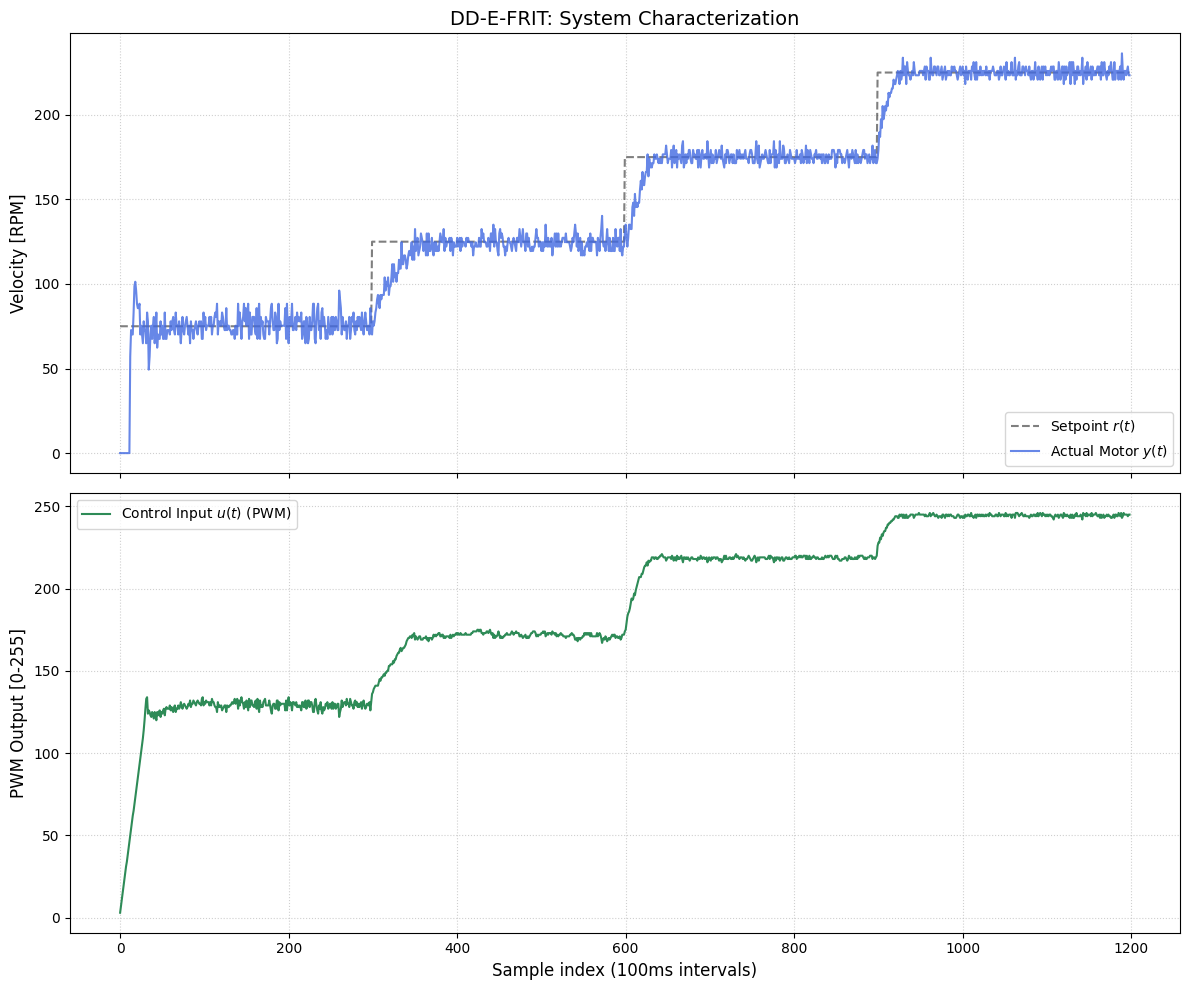

In [151]:
df2=pd.read_csv("../data/esp32/dd_efrit_run.csv")


fig,(ax1,ax2)=plt.subplots(2,1,figsize=(12,10),sharex=True)

ax1.plot(df2['SetPoint'],'k--',alpha=0.5,label='Setpoint $r(t)$')
ax1.plot(df2['RPM'],'royalblue',alpha=0.8,label='Actual Motor $y(t)$')

ax1.set_title("DD-E-FRIT: System Characterization",fontsize=14)
ax1.set_ylabel("Velocity [RPM]",fontsize=12)
ax1.legend(loc='lower right')
ax1.grid(True,linestyle=':',alpha=0.6)

ax2.plot(df2['PWM'],'seagreen',label='Control Input $u(t)$ (PWM)')
ax2.set_ylabel("PWM Output [0-255]",fontsize=12)
ax2.set_xlabel("Sample index (100ms intervals)",fontsize=12)
ax2.legend(loc='upper left')
ax2.grid(True,linestyle=':',alpha=0.6)

plt.tight_layout()
plt.show()

### Performance metrics

In [152]:
def calculate_metrics(data, name="Dataset"):
    error=data['SetPoint']-data['RPM']
    mae=np.mean(np.abs(error))                    
    rmse=np.sqrt(np.mean(error**2))
    iae=np.sum(np.abs(error))

    delta_u = np.diff(data['PWM'])                 
    tv=np.sum(np.abs(delta_u))
    delta_u_sq=np.sum(delta_u**2)     
    
    max_error = np.max(np.abs(error))
    
    return {
        "Dataset": name,
        "MAE (RPM Error)": round(mae, 3),
        "RMSE (RPM Error)": round(rmse, 3),
        "Integral Absolute Error": round(iae, 3),
        "Max Error (RPM)": round(max_error, 3),
        "Control TV (Sum |ΔPWM|)": round(tv, 3),
        "Control Effort (Sum ΔPWM^2)": round(delta_u_sq, 3)
    }

metrics = [
    calculate_metrics(df, "Initial (Static PID)"),
    calculate_metrics(df2, "Final (Optimized PID)"),
]

metrics_df = pd.DataFrame(metrics)

print("Performance Metrics Comparison")
print(metrics_df.to_string(index=False))

Performance Metrics Comparison
              Dataset  MAE (RPM Error)  RMSE (RPM Error)  Integral Absolute Error  Max Error (RPM)  Control TV (Sum |ΔPWM|)  Control Effort (Sum ΔPWM^2)
 Initial (Static PID)            6.616            11.026                  7912.20             75.0                     2214                         7586
Final (Optimized PID)            5.937            11.778                  7118.35             75.0                     1572                         4108


### Side-by-side comparison

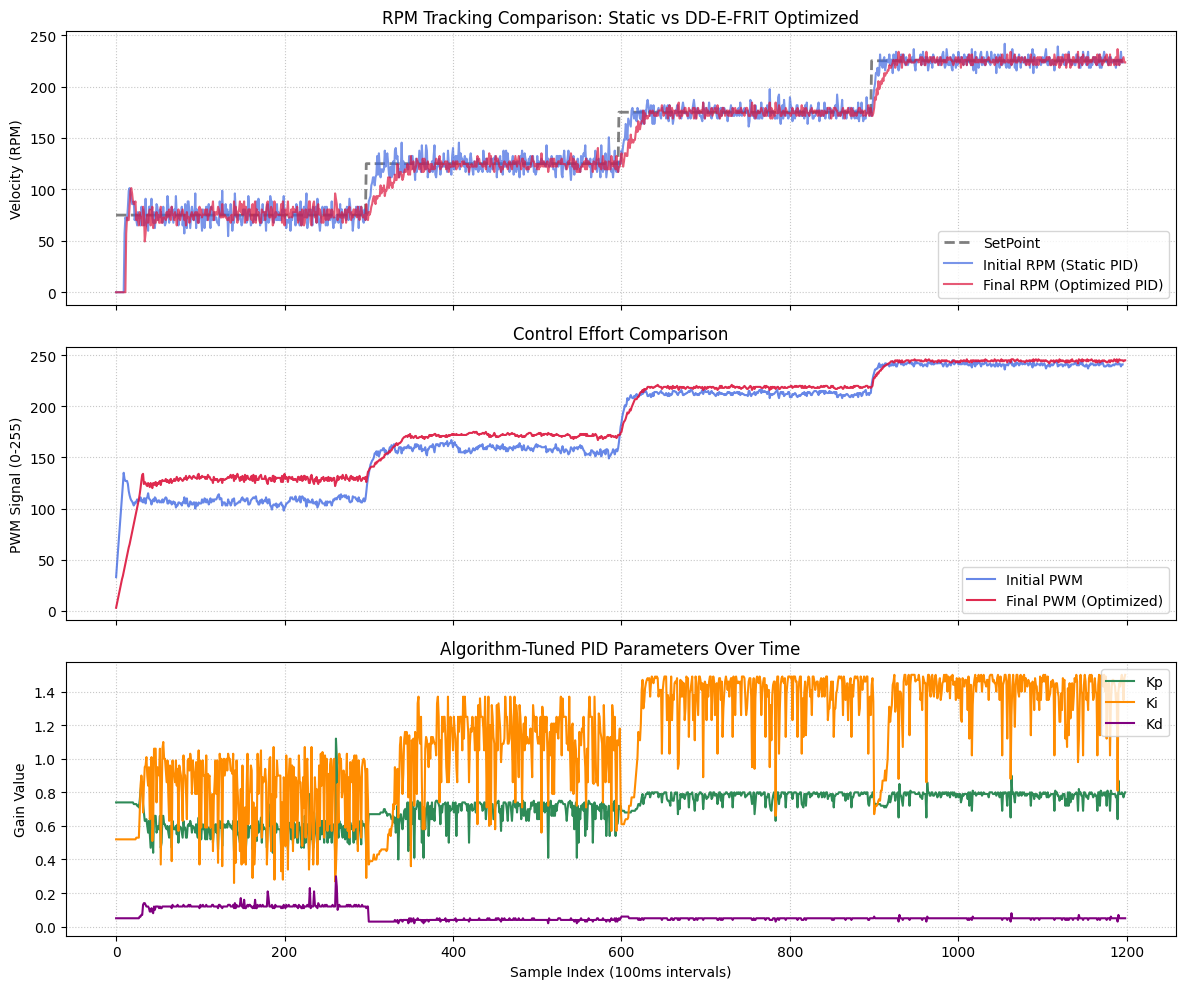

In [153]:

fig,axes= plt.subplots(3, 1, figsize=(12, 10), sharex=True)

axes[0].plot(df['SetPoint'], 'k--', alpha=0.5 , label='SetPoint', linewidth=2)
axes[0].plot(df['RPM'], label='Initial RPM (Static PID)', alpha=0.7, color='royalblue')
axes[0].plot(df2['RPM'], label='Final RPM (Optimized PID)', alpha=0.7, color='crimson')
axes[0].set_title('RPM Tracking Comparison: Static vs DD-E-FRIT Optimized', fontsize=12)
axes[0].set_ylabel('Velocity (RPM)')
axes[0].legend(loc='lower right')
axes[0].grid(True, linestyle=':', alpha=0.7)

axes[1].plot(df['PWM'], label='Initial PWM', alpha=0.8, color='royalblue')
axes[1].plot(df2['PWM'], label='Final PWM (Optimized)', alpha=0.9, color='crimson')
axes[1].set_title('Control Effort Comparison', fontsize=12)
axes[1].set_ylabel('PWM Signal (0-255)')
axes[1].legend(loc='lower right')
axes[1].grid(True, linestyle=':', alpha=0.7)

axes[2].plot(df2['Kp'], label='Kp', color='seagreen')
axes[2].plot(df2['Ki'], label='Ki', color='darkorange')
axes[2].plot(df2['Kd'], label='Kd', color='purple')
axes[2].set_title('Algorithm-Tuned PID Parameters Over Time', fontsize=12)
axes[2].set_xlabel('Sample Index (100ms intervals)')
axes[2].set_ylabel('Gain Value')
axes[2].legend(loc='upper right')
axes[2].grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

### Extended metrics and per-setpoint breakdown

In [ ]:
def calculate_metrics(data, name="Dataset"):
    error = data['SetPoint'] - data['RPM']
    mae = np.mean(np.abs(error))                    
    rmse = np.sqrt(np.mean(error**2))
    iae = np.sum(np.abs(error))
    mean_error=np.mean(error)

    delta_u = np.diff(data['PWM'])                 
    tv = np.sum(np.abs(delta_u))
    delta_u_sq = np.sum(delta_u**2) 

    error_std=np.std(error)    
    
    max_error = np.max(np.abs(error))
    
    return {
        "Dataset": name,
        "MAE (RPM Error)": round(mae, 3),
        "RMSE (RPM Error)": round(rmse, 3),
        "Integral Absolute Error": round(iae, 3),
        "Average Mean": round(mean_error, 3),
        "Max Error (RPM)": round(max_error, 3),
        "Control TV (Sum |ΔPWM|)": round(tv, 3),
        "Control Effort (Sum ΔPWM^2)": round(delta_u_sq, 3),
        "Std error": round(error_std, 3)
    }


def calculate_per_setpoint(data, name="Dataset"):
    rows = []
    
    for sp in sorted(data['SetPoint'].unique()):
        subset = data[data['SetPoint'] == sp]
        error = subset['SetPoint'] - subset['RPM']
        
        error_std = np.std(error)
        rpm_std = np.std(subset['RPM'])
        mean_err = np.mean(error)
        mae = np.mean(np.abs(error))
        
        rows.append({
            "Dataset": name,
            "Setpoint": int(sp),
            "Mean Error": round(mean_err, 2),
            "MAE": round(mae, 2),
            "Error Std": round(error_std, 2),
            "RPM Std": round(rpm_std, 2),
            "N samples": len(subset)
        })
    
    return rows

metrics = [
    calculate_metrics(df,  "Initial (Static PID)"),
    calculate_metrics(df2, "Final (Optimized PID)"),
]
metrics_df = pd.DataFrame(metrics)

print("Performance Metrics")
print(metrics_df.to_string(index=False))

per_sp_rows = []
per_sp_rows += calculate_per_setpoint(df,  "Initial (Static PID)")
per_sp_rows += calculate_per_setpoint(df2, "Final (Optimized PID)")

per_sp_df = pd.DataFrame(per_sp_rows)

print()
print(per_sp_df.to_string(index=False))

Performance Metrics
              Dataset  MAE (RPM Error)  RMSE (RPM Error)  Integral Absolute Error  Average Mean  Max Error (RPM)  Control TV (Sum |ΔPWM|)  Control Effort (Sum ΔPWM^2)  Std error
 Initial (Static PID)            6.616            11.026                  7912.20         1.470             75.0                     2214                         7586     10.928
Final (Optimized PID)            5.937            11.778                  7118.35         2.632             75.0                     1572                         4108     11.480

              Dataset  Setpoint  Mean Error  MAE  Error Std  RPM Std  Std Difference  N samples
 Initial (Static PID)        75        2.28 9.08      15.98    15.98             0.0        297
 Initial (Static PID)       125        1.31 7.15       9.84     9.84             0.0        300
 Initial (Static PID)       175        1.44 5.64       8.73     8.73             0.0        300
 Initial (Static PID)       225        0.85 4.61       7.03  